0. Descriptive analysis:

In [9]:
import pandas as pd

In [10]:
orders_df = pd.read_csv("orders-1.csv")

In [11]:
revenue_df = pd.read_csv("company_quarterly_revenue_raw.csv")

In [12]:
shipments_df = pd.read_csv("shipments.csv")

In [13]:
orders_df.shape

(20, 5)

In [14]:
orders_df.head(10)

,order_id,customer_id,amount,company,quarter
0,O1000,C106,26,Umbrella,2024-Q4
1,O1001,C105,48,Umbrella,2023-Q3
2,O1002,C103,155,Globex,2025-Q2
3,O1003,C100,38,Acme,2023-Q4
4,O1004,C103,136,Globex,2023-Q3
5,O1005,C107,144,Soylent,2023-Q4
6,O1006,C101,62,Acme,2024-Q3
7,O1007,C103,64,Globex,2025-Q2
8,O1008,C106,48,Umbrella,2025-Q2
9,O1009,C105,122,Umbrella,2023-Q2


The file orders-1.csv is tidy, as it satisfies the 3 rules of tidiness, which are 
1. Each variable forms a column.
2. Each observation forms a row
3. Each value forms a cell.

In [16]:
revenue_df.shape

(5, 13)

In [17]:
revenue_df.head()

,company,2023-Q1,2023-Q2,2023-Q3,2023-Q4,2024-Q1,2024-Q2,2024-Q3,2024-Q4,2025-Q1,2025-Q2,2025-Q3,2025-Q4
0,Acme,13.5,14.1,15.9,16.8,15.6,16.7,18.4,17.1,18.6,19.9,20.5,20.3
1,Globex,10.3,8.7,9.4,10.7,13.5,12.0,11.6,11.6,14.0,13.8,15.9,14.0
2,Initech,16.9,15.7,16.7,16.8,17.1,17.9,18.1,18.4,18.6,17.9,20.2,22.3
3,Soylent,10.8,12.9,14.9,15.4,15.5,19.4,20.1,22.1,23.0,22.9,22.0,23.6
4,Umbrella,8.1,6.1,7.7,8.7,9.6,8.7,11.7,10.4,9.8,11.8,12.4,14.3


The dataset company_quarterly_revenue_raw.csv is not tidy, as the quarters are spread across multiple columns rather than being captured in a single quarter column, 
which violates the rule of tidiness.

In [18]:
shipments_df.head(10)

,order_id,tracking
0,O1000,O1000-1
1,O1001,O1001-1
2,O1001,O1001-2
3,O1002,O1002-1
4,O1003,O1003-1
5,O1003,O1003-2
6,O1004,O1004-1
7,O1004,O1004-2
8,O1004,O1004-3
9,O1005,O1005-1


In [19]:
shipments_df.shape

(35, 2)

The dataset shipments.csv violates the rule of tidiness, as several observations are repeated, violating the rule that each observation forms a single row. 

In [ ]:
1. Revenue table

The dataset company_quarterly_revenue_raw.csv is wide and not tidy, as the quarters are spread across multiple columns rather than being captured in a single quarter column, 
which violates the rule of tidiness.

In [20]:
revenue_df_long = revenue_df.melt(id_vars=['company'], var_name='quarter', value_name='revenue')

In [21]:
print(revenue_df_long)

     company  quarter  revenue
0       Acme  2023-Q1     13.5
1     Globex  2023-Q1     10.3
2    Initech  2023-Q1     16.9
3    Soylent  2023-Q1     10.8
4   Umbrella  2023-Q1      8.1
5       Acme  2023-Q2     14.1
6     Globex  2023-Q2      8.7
7    Initech  2023-Q2     15.7
8    Soylent  2023-Q2     12.9
9   Umbrella  2023-Q2      6.1
10      Acme  2023-Q3     15.9
11    Globex  2023-Q3      9.4
12   Initech  2023-Q3     16.7
13   Soylent  2023-Q3     14.9
14  Umbrella  2023-Q3      7.7
15      Acme  2023-Q4     16.8
16    Globex  2023-Q4     10.7
17   Initech  2023-Q4     16.8
18   Soylent  2023-Q4     15.4
19  Umbrella  2023-Q4      8.7
20      Acme  2024-Q1     15.6
21    Globex  2024-Q1     13.5
22   Initech  2024-Q1     17.1
23   Soylent  2024-Q1     15.5
24  Umbrella  2024-Q1      9.6
25      Acme  2024-Q2     16.7
26    Globex  2024-Q2     12.0
27   Initech  2024-Q2     17.9
28   Soylent  2024-Q2     19.4
29  Umbrella  2024-Q2      8.7
30      Acme  2024-Q3     18.4
31    Gl

2. Duplicate keyss?

orders.csv: order_id is unique because each observation forms a row.
shipments.csv: order_id is not unique, with duplicate entries because some orders have multiple tracking numbers.  
Cardinality Implication: Because orders has a unique primary key and shipments has a one-to-many/many-to-one relationship relative to orders, joining orders(left) with shipments(right) creates a one-to-many relationship. 

3. Join orders and shipments correctly. 

In [22]:
orders_joined = pd.merge(orders_df, shipments_df, on='order_id', how='left')
print(orders_joined.head())
print("Joined shape:", orders_joined.shape)

  order_id customer_id  amount   company  quarter tracking
0    O1000        C106      26  Umbrella  2024-Q4  O1000-1
1    O1001        C105      48  Umbrella  2023-Q3  O1001-1
2    O1001        C105      48  Umbrella  2023-Q3  O1001-2
3    O1002        C103     155    Globex  2025-Q2  O1002-1
4    O1003        C100      38      Acme  2023-Q4  O1003-1
Joined shape: (35, 6)


In [23]:
mean_per_customer_joined = orders_joined.groupby('customer_id')['amount'].mean()
print(mean_per_customer_joined)

customer_id
C100     38.000
C101     62.000
C102    105.000
C103    112.375
C104     33.000
C105     67.625
C106     62.250
C107    106.000
Name: amount, dtype: float64


In [24]:
mean_amount_per_customer = orders_df.groupby('customer_id')['amount'].mean()
print(mean_amount_per_customer)

customer_id
C100     38.00
C101     62.00
C102    105.00
C103    111.60
C104     33.00
C105     67.25
C106     59.50
C107     96.50
Name: amount, dtype: float64


The orders_df shows the correct mean per customer as the orders.csv table contains each unique order exactly once. Grouping by customer_id here correctly averages the actual monetary value of each customer's orders.

4. Produce one analysis-ready table: 

In [25]:
analysis_ready_df = orders_joined.merge(revenue_df_long, on='company', how='left')
analysis_ready_df = analysis_ready_df.reset_index(drop=True)
analysis_ready_df = analysis_ready_df.rename(columns={
    'amount': 'order_amount', 
    'revenue': 'company_quarterly_revenue'
})
print(analysis_ready_df.head())

  order_id customer_id  order_amount   company quarter_x tracking quarter_y  \
0    O1000        C106            26  Umbrella   2024-Q4  O1000-1   2023-Q1   
1    O1000        C106            26  Umbrella   2024-Q4  O1000-1   2023-Q2   
2    O1000        C106            26  Umbrella   2024-Q4  O1000-1   2023-Q3   
3    O1000        C106            26  Umbrella   2024-Q4  O1000-1   2023-Q4   
4    O1000        C106            26  Umbrella   2024-Q4  O1000-1   2024-Q1   

   company_quarterly_revenue  
0                        8.1  
1                        6.1  
2                        7.7  
3                        8.7  
4                        9.6  


Visualization: 

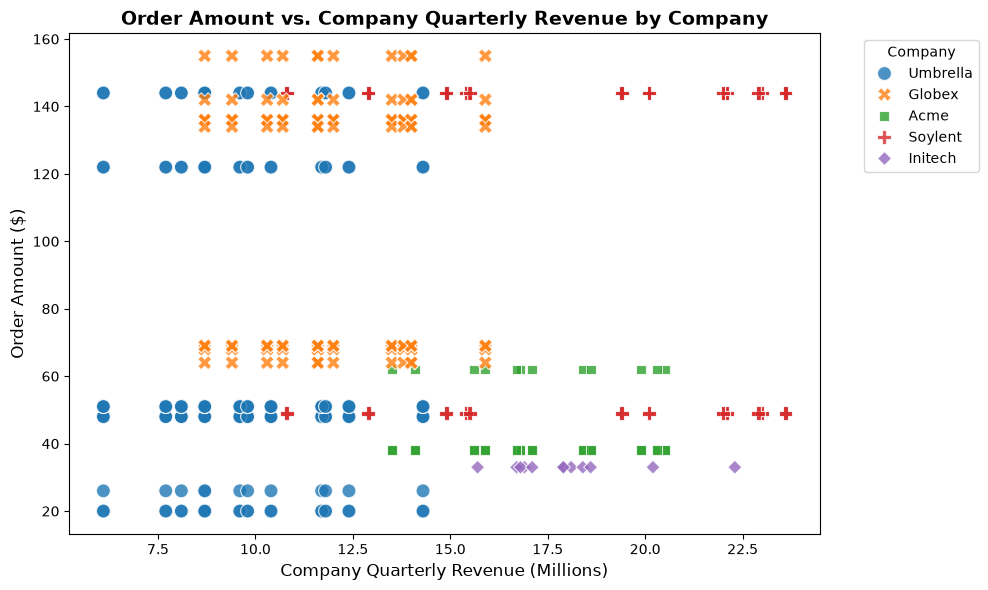

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the visualization figure
plt.figure(figsize=(10, 6))

# Create a scatter plot showing order amount vs company quarterly revenue, colored by company
sns.scatterplot(
    data=analysis_ready_df, 
    x='company_quarterly_revenue', 
    y='order_amount', 
    hue='company', 
    style='company', 
    s=100, 
    alpha=0.8
)

# Add titles and labels
plt.title('Order Amount vs. Company Quarterly Revenue by Company', fontsize=14, fontweight='bold')
plt.xlabel('Company Quarterly Revenue (Millions)', fontsize=12)
plt.ylabel('Order Amount ($)', fontsize=12)

# Move legend outside the plot for cleanliness
plt.legend(title='Company', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()